# Vehicle Insurance Claim Fraud Detection
## Classification using five Machine Learning algorithms

**Course:** Machine Learning – Assignment 2  
**Programme:** BITS Pilani WILP  
**Student ID:** 2025NS04074  
**Dataset:** Kaggle – Vehicle Claim Fraud Detection  
**Target field:** `FraudFound_P`

# TABLE OF CONTENTS

1. [Problem definition](#part-1)
2. [Import libraries and load data](#part-2)
3. [Understand the dataset](#part-3)
4. [Data quality checks](#part-4)
5. [Exploratory data analysis](#part-5)
6. [Prepare features and target](#part-6)
7. [Preprocess the data](#part-7)
8. [Split into training and testing sets](#part-8)
9. [Logistic Regression](#part-9)
10. [Decision Tree using Entropy](#part-10)
11. [K-Nearest Neighbours](#part-11)
12. [Gaussian Naive Bayes](#part-12)
13. [Support Vector Machine](#part-13)
14. [Compare all five classifiers and calculate the six required metrics](#part-14)
15. [Confusion matrices and ROC curves](#part-15)
16. [Save models and test data](#part-16)
17. [Model-wise observations, overall winner, limitations and submission evidence](#part-17)

---

<a id="part-1"></a>
# <span style="color:#C00000">1. PROBLEM DEFINITION</span>

Vehicle insurance claim fraud is a relevant classification problem because historical claim records may contain patterns associated with fraudulent and non-fraudulent claims. A classifier can help identify claims that may deserve closer examination.

**Kaggle link:** https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection

**Problem statement:** Using the available claim, policy, vehicle and claimant attributes to classify a record as:

- `0` – Non-fraudulent claim
- `1` – Fraudulent claim

<a id="part-2"></a>
# <span style="color:#C00000">2. IMPORT LIBRARIES AND LOAD DATA</span>

Libraries below support data handling, charts, preprocessing, the five classifiers and model assessment. 

In [2]:
from pathlib import Path
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    matthews_corrcoef, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore",message="Could not find the number of physical cores.*",category=UserWarning,)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
TARGET = "FraudFound_P"

# Resolve the project directory whether Jupyter was opened from the root or notebooks folder.
CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR if (CURRENT_DIR / "data").is_dir() else CURRENT_DIR.parent
DATA_FILE = PROJECT_DIR / "data" / "fraud_oracle.csv"

print("Project directory:", PROJECT_DIR)
print("Dataset file:", DATA_FILE)

Project directory: /home/s2025ns04074/workspace/claim_fraud_project
Dataset file: /home/s2025ns04074/workspace/claim_fraud_project/data/fraud_oracle.csv


In [3]:
claims = pd.read_csv(DATA_FILE)
print("Dataset loaded.")
print("Number of records:", claims.shape[0])
print("Number of columns:", claims.shape[1])
display(claims.head())

Dataset loaded.
Number of records: 15420
Number of columns: 33


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


<a id="part-3"></a>
# <span style="color:#C00000">3. UNDERSTAND THE DATASET</span>

Initial data review covers the sample, dimensions, column names, data types and summary values before the data is prepared.

In [4]:
print("Dataset dimensions:", claims.shape)
print("\nColumn names:")
print(claims.columns.tolist())
print("\nData types and non-null counts:")
claims.info()

Dataset dimensions: (15420, 33)

Column names:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-

### <span style="color:#C00000">Definition of Features</span>

* **Month**: The month in which the insurance claim was made.
* **WeekOfMonth**: The week of the month in which the insurance claim was made.
* **DayOfWeek**: The day of the week on which the insurance claim was made. 
* **Make**: The manufacturer of the vehicle involved in the claim. 
* **AccidentArea**: The area where the accident occurred (e.g., urban, rural).
* **DayOfWeekClaimed**: The day of the week on which the insurance claim was processed. 
* **MonthClaimed**: The month in which the insurance claim was processed.
* **WeekOfMonthClaimed**: The week of the month in which the insurance claim was processed. 
* **Sex**: The gender of the policyholder.
* **MaritalStatus**: The Martial status of the policyholder. 
* **Age**: The age of the policyholder.
* **Fault**: Indicates whether the policyholder was at fault in the accident.
* **PolicyType**: The type of insurance policy (e.g., comprehensive, third-party).
* **VehicleCategory**: The category of the vehicle (e.g., sedan, SUV).
* **VehiclePrice**: The price of vehicle.
* **FraudFound_P**: Indicates whether fraud was detected in the insurance claim.
* **PolicyNumber**: The unique identifier for the insurance policy.
* **RepNumber**: The unique identifier for the insurance representative handling the claim. 
* **Deductible**: The amount that the policy holder must pay out of pocket before the insurance company pays the remaining costs.
* **DriverRating**: The rating of the driver, often based on driving history or other factors.
* **Days_Policy_Accident**: The number of days since the policy was issued until the accident occurred.
* **Days_Policy_Claim**: The number of days since the policy was issued until the claim was made.
* **PastNumberOfClaims**: The number of claims previously made by the policyholder.
* **AgeOfVehicle**: The age of the vehicle involved in the claim.
* **AgeOfPolicyHolder**: The age of the policyholder.
* **PoliceReportFiled**: Indicates whether a police report was filed for the accident.
* **WitnessPresent**: Indicates whether a witness was present at the scene of the accident.
* **AgentType**: The type of insurance agent handling the policy (e.g., internal, external) 
* **NumberOfSuppliments**: The number of supplementary documents or claims related to the main claim, categorized into ranges.
* **AddressChange_Claim**: Indicates whether the address of the policyholder was changed at the time of the claim, categorized into ranges.
* **NumberOfCars**: The number of cars insured under the policy, categorized into ranges.
* **Year**: The year in which the claim was made or processed. 
* **BasePolicy**: The base policy type (e.g., Liability, Collision, All Perils). 


In [5]:
display(claims.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Month,15420,12,Jan,1411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonth,15420.0,NaN,NaN,NaN,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
DayOfWeek,15420,7,Monday,2616,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Make,15420,19,Pontiac,3837,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccidentArea,15420,2,Urban,13822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DayOfWeekClaimed,15420,8,Monday,3757,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthClaimed,15420,13,Jan,1446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeekOfMonthClaimed,15420.0,NaN,NaN,NaN,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Sex,15420,2,Male,13000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,15420,4,Married,10625,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Number of distinct values in each column:")
display(claims.nunique(dropna=False).sort_values(ascending=False).to_frame("Distinct values"))

Number of distinct values in each column:


,Distinct values
PolicyNumber,15420
Age,66
Make,19
RepNumber,16
MonthClaimed,13
Month,12
PolicyType,9
AgeOfPolicyHolder,9
DayOfWeekClaimed,8
AgeOfVehicle,8


<a id="part-4"></a>
# <span style="color:#C00000">4. DATA QUALITY CHECKS</span>

Check missing values, duplicate rows, target validity and unusual category values. The result of each check should be reviewed before proceeding; do not remove records without a reason.

In [7]:
missing_summary = claims.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].to_frame("Missing values"))
print("Total missing cells:", int(claims.isna().sum().sum()))
print("Duplicate complete rows:", int(claims.duplicated().sum()))

,Missing values


Total missing cells: 0
Duplicate complete rows: 0


In [8]:
print("Target values:", sorted(claims[TARGET].dropna().unique().tolist()))
print("Target missing values:", claims[TARGET].isna().sum())
print("Target counts:")
display(claims[TARGET].value_counts(dropna=False).sort_index())

Target values: [0, 1]
Target missing values: 0
Target counts:


FraudFound_P
0    14497
1      923
Name: count, dtype: int64

In [7]:
# Review the distinct values in categorical columns for unexpected labels.
categorical_columns_raw = claims.select_dtypes(exclude="number").columns.tolist()
for column in categorical_columns_raw:
    print("\n", column)
    print(claims[column].value_counts(dropna=False).head(20))


 Month
Month
Jan    1411
May    1367
Mar    1360
Jun    1321
Oct    1305
Dec    1285
Apr    1280
Feb    1266
Jul    1257
Sep    1240
Nov    1201
Aug    1127
Name: count, dtype: int64

 DayOfWeek
DayOfWeek
Monday       2616
Friday       2445
Tuesday      2300
Thursday     2173
Wednesday    2159
Saturday     1982
Sunday       1745
Name: count, dtype: int64

 Make
Make
Pontiac      3837
Toyota       3121
Honda        2801
Mazda        2354
Chevrolet    1681
Accura        472
Ford          450
VW            283
Dodge         109
Saab          108
Mercury        83
Saturn         58
Nisson         30
BMW            15
Jaguar          6
Porche          5
Mecedes         4
Ferrari         2
Lexus           1
Name: count, dtype: int64

 AccidentArea
AccidentArea
Urban    13822
Rural     1598
Name: count, dtype: int64

 DayOfWeekClaimed
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               

### Review of unusual or sentinel values

The following checks highlight values that may need domain interpretation. They are reported for review and are not automatically deleted or recoded.

In [9]:
review_columns = ["Age", "MonthClaimed", "DayOfWeekClaimed", "Days_Policy_Accident",
                  "Days_Policy_Claim", "NumberOfSuppliments", "AddressChange_Claim"]
for field in review_columns:
    if field in claims.columns:
        print(f"\\n{field}:")
        print(claims[field].value_counts(dropna=False).head(20))

if "Age" in claims.columns:
    print("\\nRecords with Age = 0:", int((claims["Age"] == 0).sum()))
if "MonthClaimed" in claims.columns:
    print("Records with MonthClaimed = '0':",
          int((claims["MonthClaimed"].astype(str) == "0").sum()))

\nAge:
Age
30    596
33    574
34    573
35    569
28    560
29    552
31    550
32    544
27    540
26    535
39    435
41    423
44    411
37    410
36    406
43    404
42    401
45    386
38    384
40    383
Name: count, dtype: int64
\nMonthClaimed:
MonthClaimed
Jan    1446
May    1411
Mar    1348
Oct    1339
Jun    1293
Feb    1287
Nov    1285
Apr    1271
Sep    1242
Jul    1225
Dec    1146
Aug    1126
0         1
Name: count, dtype: int64
\nDayOfWeekClaimed:
DayOfWeekClaimed
Monday       3757
Tuesday      3375
Wednesday    2951
Thursday     2660
Friday       2497
Saturday      127
Sunday         52
0               1
Name: count, dtype: int64
\nDays_Policy_Accident:
Days_Policy_Accident
more than 30    15247
none               55
8 to 15            55
15 to 30           49
1 to 7             14
Name: count, dtype: int64
\nDays_Policy_Claim:
Days_Policy_Claim
more than 30    15342
15 to 30           56
8 to 15            21
none                1
Name: count, dtype: int64
\nNumberOfS

**Identifier review:** `PolicyNumber` is a record identifier, not a general behavioural attribute. It will be excluded from the model input. Other fields such as `RepNumber` are retained at this stage; their predictive usefulness and possible operational bias should be considered when interpreting results.

<a id="part-5"></a>
# <span style="color:#C00000">5. EXPLORATORY DATA ANALYSIS</span>

The plots in this section are used to understand the class balance and how selected claim attributes are distributed. They are descriptive summaries, not evidence that a field causes fraud.

,Records,Percentage
FraudFound_P,,
0,14497,94.01
1,923,5.99


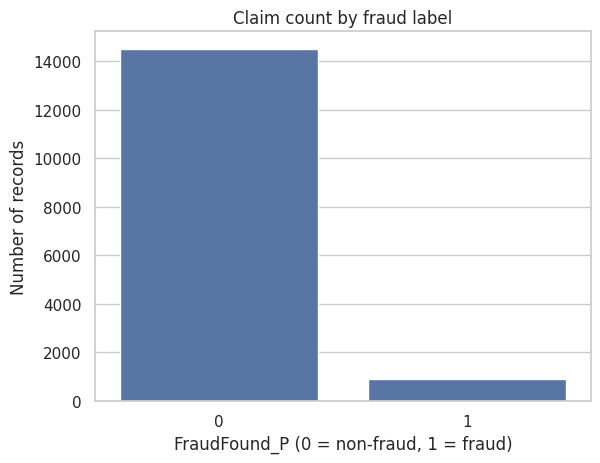

In [10]:
target_count = claims[TARGET].value_counts().sort_index()
target_percent = claims[TARGET].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"Records": target_count, "Percentage": target_percent.round(2)}))
ax = sns.countplot(data=claims, x=TARGET)
ax.set_title("Claim count by fraud label")
ax.set_xlabel("FraudFound_P (0 = non-fraud, 1 = fraud)")
ax.set_ylabel("Number of records")
plt.show()

In [11]:
numeric_columns = claims.select_dtypes(include="number").columns.tolist()
numeric_predictors_raw = [c for c in numeric_columns if c not in [TARGET, "PolicyNumber"]]
display(claims[numeric_predictors_raw].describe().T)

,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.0,3.0,4.0,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.0,3.0,4.0,5.0
Age,15420.0,39.855707,13.492377,0.0,31.0,38.0,48.0,80.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.0,8.0,12.0,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.0,400.0,400.0,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.0,2.0,3.0,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.0,1995.0,1996.0,1996.0


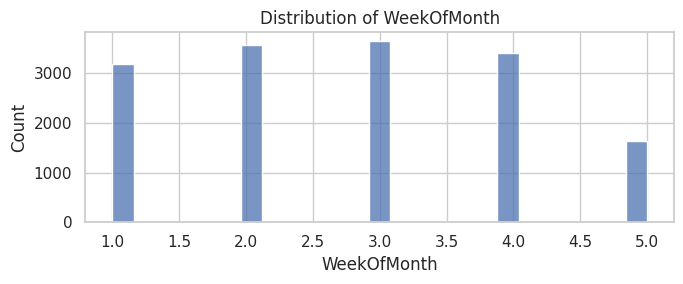

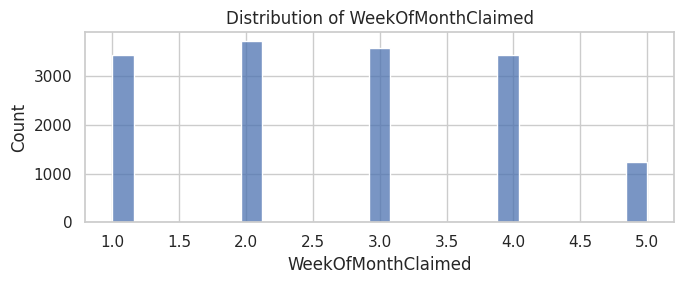

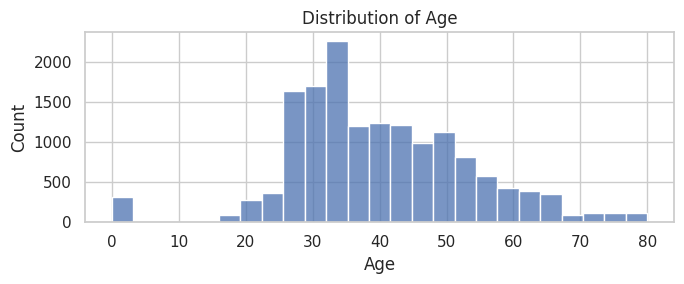

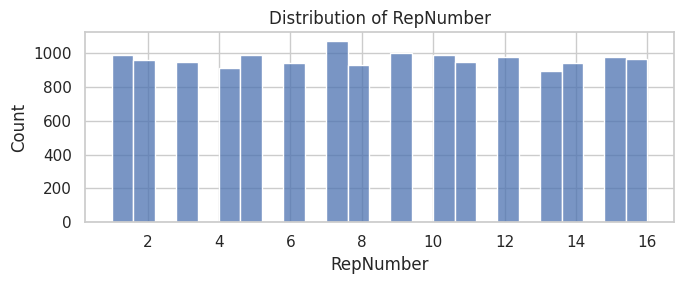

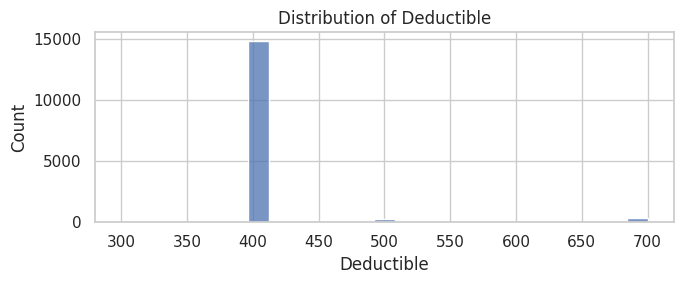

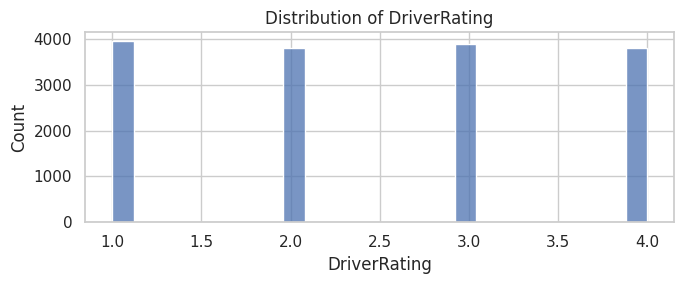

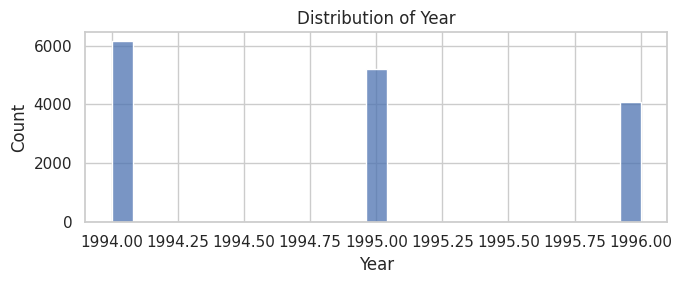

In [12]:
# Inspect distributions of numeric predictors.
for field in numeric_predictors_raw:
    plt.figure(figsize=(7, 3))
    sns.histplot(data=claims, x=field, bins=25, kde=False)
    plt.title("Distribution of " + field)
    plt.tight_layout()
    plt.show()

In [12]:
# Compare fraud proportion across a few business-readable categorical fields.
fields_to_compare = ["AccidentArea", "Fault", "VehicleCategory", "AgentType", "BasePolicy"]
for field in fields_to_compare:
    if field in claims.columns:
        fraud_by_group = claims.groupby(field, dropna=False)[TARGET].agg(
            claim_count="count", fraud_rate="mean"
        ).sort_values("fraud_rate", ascending=False)
        display(fraud_by_group.style.format({"fraud_rate": "{:.2%}"}).set_caption("Fraud proportion by " + field))

,claim_count,fraud_rate
AccidentArea,,
Rural,1598,8.32%
Urban,13822,5.72%


,claim_count,fraud_rate
Fault,,
Policy Holder,11230,7.89%
Third Party,4190,0.88%


,claim_count,fraud_rate
VehicleCategory,,
Utility,391,11.25%
Sedan,9671,8.22%
Sport,5358,1.57%


,claim_count,fraud_rate
AgentType,,
External,15179,6.05%
Internal,241,1.66%


,claim_count,fraud_rate
BasePolicy,,
All Perils,4449,10.16%
Collision,5962,7.30%
Liability,5009,0.72%


<a id="part-6"></a>
# <span style="color:#C00000">6. PREPARE FEATURES AND TARGET</span>

The target is separated from the predictors. The policy number is removed from the predictors because it identifies a policy record rather than describing claim characteristics.

In [13]:
X = claims.drop(columns=[TARGET, "PolicyNumber"], errors="ignore").copy()
y = claims[TARGET].astype(int).copy()

print("Predictor matrix:", X.shape)
print("Target vector:", y.shape)
print("Target labels:", sorted(y.unique()))
print("Predictor fields:")
print(X.columns.tolist())

Predictor matrix: (15420, 31)
Target vector: (15420,)
Target labels: [np.int64(0), np.int64(1)]
Predictor fields:
['Month', 'WeekOfMonth', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'WeekOfMonthClaimed', 'Sex', 'MaritalStatus', 'Age', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'RepNumber', 'Deductible', 'DriverRating', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'Year', 'BasePolicy']


<a id="part-7"></a>
# <span style="color:#C00000">7. PREPROCESS THE DATA</span>

The preprocessing workflow covers missing-value treatment, categorical encoding and feature scaling. Here the transformations are placed in a `ColumnTransformer` and fitted as part of each model pipeline. This keeps the training and testing process consistent and prevents the test set from influencing imputation, encoding or scaling parameters.

- Numeric fields: median imputation followed by standardisation.
- Categorical fields: most-frequent imputation followed by one-hot encoding.
- `handle_unknown="ignore"` allows the model to process a category not seen during training.

In [14]:
numeric_fields = X.select_dtypes(include="number").columns.tolist()
categorical_fields = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric fields:", numeric_fields)
print("\nCategorical fields:", categorical_fields)
print("\nNumber of numeric fields:", len(numeric_fields))
print("Number of categorical fields:", len(categorical_fields))

Numeric fields: ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'RepNumber', 'Deductible', 'DriverRating', 'Year']

Categorical fields: ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy']

Number of numeric fields: 7
Number of categorical fields: 24


In [15]:
numeric_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median")),
    ("standardise", StandardScaler())
])

categorical_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

def make_preprocessor():
    numeric_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="median")),
        ("standardise", StandardScaler())
    ])
    categorical_steps = Pipeline(steps=[
        ("fill_missing", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_steps, numeric_fields),
        ("categorical", categorical_steps, categorical_fields)
    ], remainder="drop", sparse_threshold=0)

print("Preprocessing function is ready.")

Preprocessing function is ready.


<a id="part-8"></a>
# <span style="color:#C00000">8. SPLIT INTO TRAINING AND TESTING SETS</span>

A stratified split is used so that the proportion of fraud and non-fraud records is approximately maintained in both partitions. All five algorithms will use this same split.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts().sort_index().to_frame("Training records"))
print("\nTesting target distribution:")
display(y_test.value_counts().sort_index().to_frame("Testing records"))

Training features: (12336, 31)
Testing features: (3084, 31)

Training target distribution:


,Training records
FraudFound_P,
0,11598
1,738



Testing target distribution:


,Testing records
FraudFound_P,
0,2899
1,185


### Model configuration

| Classifier | Configuration used |
|---|---|
| Logistic Regression | `max_iter=2000`, `class_weight="balanced"` |
| Decision Tree | `criterion="entropy"`, `max_depth=8`, `min_samples_leaf=5`, `class_weight="balanced"` |
| KNN | `k` selected from 3, 5, 7, 9, 11 and 15 using 5-fold stratified cross-validation on training data; F1 is the selection score |
| Gaussian Naive Bayes | `GaussianNB()` |
| SVM | RBF kernel, `C=1.0`, `gamma="scale"`, `class_weight="balanced"`, probability estimates enabled |

The configurations above are used consistently in this notebook and in the companion training script.

<a id="part-9"></a>
# <span style="color:#C00000">9. LOGISTIC REGRESSION</span>

Binary Logistic Regression estimates classification, prediction and performance assessment. The scikit-learn implementation is used here, with the preprocessing steps included in the pipeline. `class_weight="balanced"` adjusts the fitting weights to account for the lower frequency of fraud cases.

In [17]:
lr_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

lr_pipeline.fit(X_train, y_train)
lr_prediction = lr_pipeline.predict(X_test)
lr_probability = lr_pipeline.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed.")
print("Test accuracy:", round(accuracy_score(y_test, lr_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, lr_prediction, zero_division=0))

/home/s2025ns04074/workspace/claim_fraud_project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:455: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Logistic Regression training completed.
Test accuracy: 0.6436

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.63      0.77      2899
           1       0.13      0.89      0.23       185

    accuracy                           0.64      3084
   macro avg       0.56      0.76      0.50      3084
weighted avg       0.94      0.64      0.74      3084



<a id="part-10"></a>
# <span style="color:#C00000">10. DECISION TREE USING ENTROPY</span>

The Decision Tree model uses `criterion="entropy"`, predictions, accuracy, a confusion matrix, a classification report and tree visualisation. We apply the entropy criterion to the claim dataset. A limited tree depth is used as a simple pre-pruning control; its effect will be assessed using the test results.

In [18]:
tree_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", DecisionTreeClassifier(
        criterion="entropy",
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

tree_pipeline.fit(X_train, y_train)
tree_prediction = tree_pipeline.predict(X_test)
tree_probability = tree_pipeline.predict_proba(X_test)[:, 1]

print("Decision Tree (Entropy) training completed.")
print("Test accuracy:", round(accuracy_score(y_test, tree_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, tree_prediction, zero_division=0))

Decision Tree (Entropy) training completed.
Test accuracy: 0.654

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.64      0.78      2899
           1       0.14      0.89      0.24       185

    accuracy                           0.65      3084
   macro avg       0.56      0.76      0.51      3084
weighted avg       0.94      0.65      0.74      3084



<a id="part-11"></a>
# <span style="color:#C00000">11. K-NEAREST NEIGHBOURS (KNN)</span>

KNN is sensitive to feature scale; the workflow also compares why feature scaling matters and demonstrates testing different neighbour counts. We use cross-validation on the training partition to select `k`; the held-out test partition is not used to select the parameter.

In [19]:
knn_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", KNeighborsClassifier())
])

knn_grid = {"classifier__n_neighbors": [3, 5, 7, 9, 11, 15]}
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_search = GridSearchCV(
    knn_pipeline,
    param_grid=knn_grid,
    scoring="f1",
    cv=folds,
    n_jobs=-1
)
knn_search.fit(X_train, y_train)

print("Selected K:", knn_search.best_params_["classifier__n_neighbors"])
print("Best mean training-fold F1:", round(knn_search.best_score_, 4))
knn_pipeline = knn_search.best_estimator_
knn_prediction = knn_pipeline.predict(X_test)
knn_probability = knn_pipeline.predict_proba(X_test)[:, 1]
print("\nClassification report:")
print(classification_report(y_test, knn_prediction, zero_division=0))

Selected K: 3
Best mean training-fold F1: 0.103

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      2899
           1       0.14      0.05      0.07       185

    accuracy                           0.92      3084
   macro avg       0.54      0.51      0.52      3084
weighted avg       0.89      0.92      0.91      3084



In [20]:
# Show the cross-validation results for the tested K values.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)[
    ["param_classifier__n_neighbors", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("param_classifier__n_neighbors")
display(knn_cv_results)

,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,3,0.102980,0.030695,1
1,5,0.056448,0.017488,2
2,7,0.023617,0.009693,3
3,9,0.013369,0.008433,4
4,11,0.008072,0.006591,5
5,15,0.000000,0.000000,6


<a id="part-12"></a>
# <span style="color:#C00000">12. GAUSSIAN NAIVE BAYES</span>

Gaussian Naive Bayes provides the probability-based classifier family. Since the dataset contains a mixture of numeric and categorical fields, categorical fields are one-hot encoded and numeric fields are standardised. The transformed matrix is dense so it can be passed to `GaussianNB`.

In [21]:
nb_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", GaussianNB())
])

nb_pipeline.fit(X_train, y_train)
nb_prediction = nb_pipeline.predict(X_test)
nb_probability = nb_pipeline.predict_proba(X_test)[:, 1]

print("Gaussian Naive Bayes training completed.")
print("Test accuracy:", round(accuracy_score(y_test, nb_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, nb_prediction, zero_division=0))

Gaussian Naive Bayes training completed.
Test accuracy: 0.0973

Classification report:
              precision    recall  f1-score   support

           0       0.96      0.04      0.08      2899
           1       0.06      0.97      0.11       185

    accuracy                           0.10      3084
   macro avg       0.51      0.51      0.10      3084
weighted avg       0.91      0.10      0.08      3084



<a id="part-13"></a>
# <span style="color:#C00000">13. SUPPORT VECTOR MACHINE (SVM)</span>

SVM is included as the fifth classifier required for the assignment. Standardisation is included in the preprocessing pipeline because the RBF SVM is sensitive to feature scale. Class weighting is used to reduce the dominance of the majority class during fitting.

In [22]:
svm_pipeline = Pipeline(steps=[
    ("prepare", make_preprocessor()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

svm_pipeline.fit(X_train, y_train)
svm_prediction = svm_pipeline.predict(X_test)
svm_probability = svm_pipeline.predict_proba(X_test)[:, 1]

print("SVM training completed.")
print("Test accuracy:", round(accuracy_score(y_test, svm_prediction), 4))
print("\nClassification report:")
print(classification_report(y_test, svm_prediction, zero_division=0))

SVM training completed.
Test accuracy: 0.7866

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.79      0.87      2899
           1       0.17      0.68      0.28       185

    accuracy                           0.79      3084
   macro avg       0.57      0.74      0.58      3084
weighted avg       0.93      0.79      0.84      3084



<a id="part-14"></a>
# <span style="color:#C00000">14. COMPARE ALL FIVE CLASSIFIERS</span>

Each model is evaluated against the same held-out test records. For each of the five classifiers, the six evaluation measures are calculated on the same held-out test set: Accuracy, AUC Score, Precision, Recall, F1 Score and Matthews Correlation Coefficient (MCC Score). Fraud (`1`) is treated as the positive class. AUC is calculated from the model's predicted probability for the positive class, not from hard class predictions. The positive class is fraud (`1`).

In [23]:
trained_models = {
    "Logistic Regression": (lr_pipeline, lr_prediction, lr_probability),
    "Decision Tree (Entropy)": (tree_pipeline, tree_prediction, tree_probability),
    "KNN": (knn_pipeline, knn_prediction, knn_probability),
    "Gaussian Naive Bayes": (nb_pipeline, nb_prediction, nb_probability),
    "SVM": (svm_pipeline, svm_prediction, svm_probability)
}

comparison_rows = []
for model_label, (fitted_model, predicted_labels, fraud_scores) in trained_models.items():
    comparison_rows.append({
        "Model": model_label,
        "Accuracy": accuracy_score(y_test, predicted_labels),
        "AUC": roc_auc_score(y_test, fraud_scores),
        "Precision": precision_score(y_test, predicted_labels, zero_division=0),
        "Recall": recall_score(y_test, predicted_labels, zero_division=0),
        "F1": f1_score(y_test, predicted_labels, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted_labels)
    })

model_results = pd.DataFrame(comparison_rows)
display(model_results.style.format({
    "Accuracy": "{:.4f}", "AUC": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}", "MCC": "{:.4f}"
}))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6436,0.8063,0.1320,0.8865,0.2299,0.2492
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657


### Required evaluation metrics – all five models

Precision, Recall, F1 and MCC are calculated from the predicted class labels. AUC Score is calculated using predicted fraud probabilities.

In [24]:
required_metric_names = {
    "Accuracy": "Accuracy",
    "AUC": "AUC Score",
    "Precision": "Precision",
    "Recall": "Recall",
    "F1": "F1 Score",
    "MCC": "Matthews Correlation Coefficient (MCC Score)"
}

required_metrics_table = model_results.rename(columns=required_metric_names).copy()
display(required_metrics_table.style.format({
    "Accuracy": "{:.4f}",
    "AUC Score": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "Matthews Correlation Coefficient (MCC Score)": "{:.4f}"
}))

# Verify that every model has a valid value for every required metric.
required_columns = [
    "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"
]
assert len(model_results) == 5, "Exactly five classifiers must be evaluated."
assert model_results["Model"].nunique() == 5, "A classifier is missing or duplicated."
assert model_results[required_columns].notna().all().all(), "One or more required metric values are missing."
assert model_results[required_columns].apply(lambda col: col.between(-1, 1).all()).all(), "A metric is outside its expected range."
assert model_results["Accuracy"].between(0, 1).all()
assert model_results["AUC"].between(0, 1).all()
assert model_results["Precision"].between(0, 1).all()
assert model_results["Recall"].between(0, 1).all()
assert model_results["F1"].between(0, 1).all()
print("Validation passed: all five models have all six required evaluation metrics.")

,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,Matthews Correlation Coefficient (MCC Score)
0,Logistic Regression,0.6436,0.8063,0.1320,0.8865,0.2299,0.2492
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657


Validation passed: all five models have all six required evaluation metrics.


### Model-wise observations and overall winner

In [25]:
# Majority-class reference: useful for interpreting accuracy on this imbalanced dataset.
majority_class_accuracy = y_test.value_counts(normalize=True).max()
print(f"Majority-class test accuracy reference: {majority_class_accuracy:.4f}")

for model_label, row in model_results.set_index("Model").iterrows():
    print("\\n" + "-" * 72)
    print(model_label)
    print("-" * 72)
    print(
        f"Accuracy = {row['Accuracy']:.4f}; AUC Score = {row['AUC']:.4f}; "
        f"Precision = {row['Precision']:.4f}; Recall = {row['Recall']:.4f}; "
        f"F1 Score = {row['F1']:.4f}; MCC Score = {row['MCC']:.4f}."
    )
    if row["Accuracy"] <= majority_class_accuracy + 0.01:
        print("Observation: Accuracy is close to the majority-class reference; "
              "the fraud-class Precision, Recall, F1 and MCC are important when judging usefulness.")
    else:
        print("Observation: Accuracy is above the majority-class reference; "
              "check fraud-class Precision and Recall to understand the classification trade-off.")
    if row["Recall"] >= 0.70 and row["Precision"] < 0.20:
        print("The model identifies a relatively large share of fraud cases, but its low Precision "
              "indicates many flagged claims may be non-fraudulent.")
    elif row["Precision"] >= 0.20 and row["Recall"] < 0.30:
        print("The model has comparatively limited fraud detection coverage; a low Recall means "
              "many actual fraud cases are not identified.")
    elif row["Recall"] >= 0.50 and row["Precision"] >= 0.20:
        print("The model shows a more balanced fraud-class Precision/Recall profile; review its "
              "F1 and MCC alongside the confusion matrix.")
    else:
        print("Review the confusion matrix and fraud-class classification report to understand "
              "the model's false-positive and false-negative behaviour.")

# Pre-defined comparison rule: F1 first, MCC second, AUC third.
ranked_results = model_results.sort_values(
    by=["F1", "MCC", "AUC"], ascending=False
).reset_index(drop=True)
overall_winner = ranked_results.iloc[0]
print("\\n" + "=" * 72)
print("OVERALL WINNER")
print("=" * 72)
print(
    f"{overall_winner['Model']} is the leading model under the stated ranking rule "
    f"(F1 Score={overall_winner['F1']:.4f}, "
    f"MCC Score={overall_winner['MCC']:.4f}, "
    f"AUC Score={overall_winner['AUC']:.4f})."
)
print("This is a result for the selected dataset and hold-out split. "
      "It should not be interpreted as proof of production readiness.")

Majority-class test accuracy reference: 0.9400
\n------------------------------------------------------------------------
Logistic Regression
------------------------------------------------------------------------
Accuracy = 0.6436; AUC Score = 0.8063; Precision = 0.1320; Recall = 0.8865; F1 Score = 0.2299; MCC Score = 0.2492.
Observation: Accuracy is close to the majority-class reference; the fraud-class Precision, Recall, F1 and MCC are important when judging usefulness.
The model identifies a relatively large share of fraud cases, but its low Precision indicates many flagged claims may be non-fraudulent.
\n------------------------------------------------------------------------
Decision Tree (Entropy)
------------------------------------------------------------------------
Accuracy = 0.6540; AUC Score = 0.7979; Precision = 0.1355; Recall = 0.8865; F1 Score = 0.2351; MCC Score = 0.2557.
Observation: Accuracy is close to the majority-class reference; the fraud-class Precision, Recall

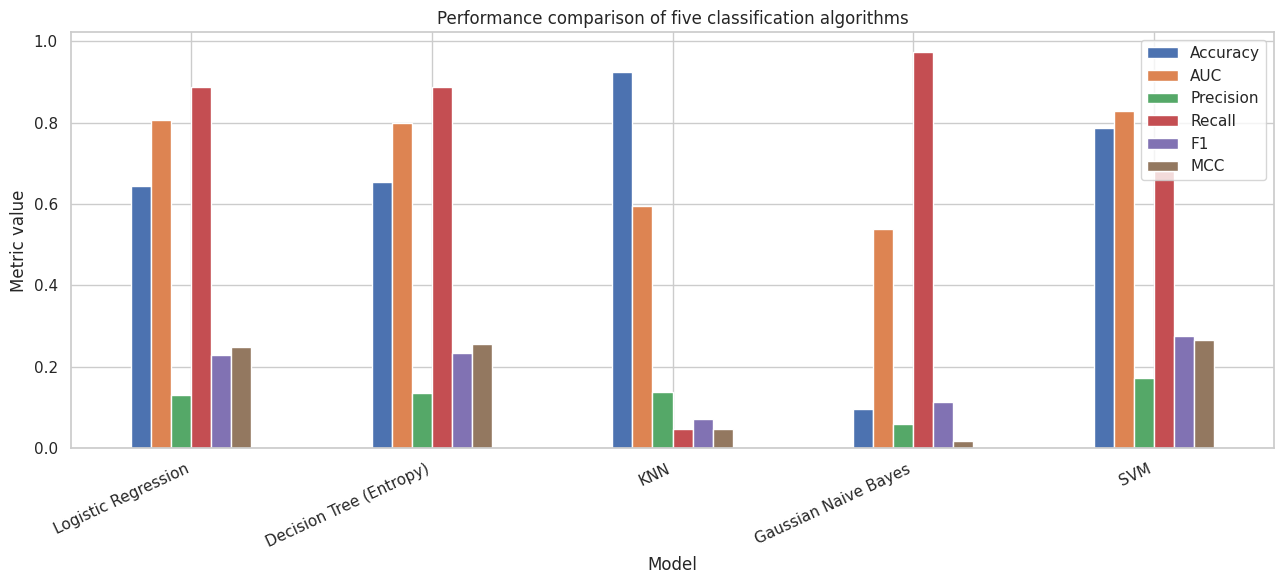

In [26]:
model_results.set_index("Model")[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].plot(
    kind="bar", figsize=(13, 6)
)
plt.title("Performance comparison of five classification algorithms")
plt.ylabel("Metric value")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

<a id="part-15"></a>
# <span style="color:#C00000">15. CONFUSION MATRICES AND ROC CURVES</span>

The confusion matrix separates correct and incorrect classifications. For this problem, false negatives are fraudulent claims predicted as non-fraud, while false positives are genuine claims predicted as fraud. ROC curves show the trade-off between true-positive and false-positive rates across thresholds.

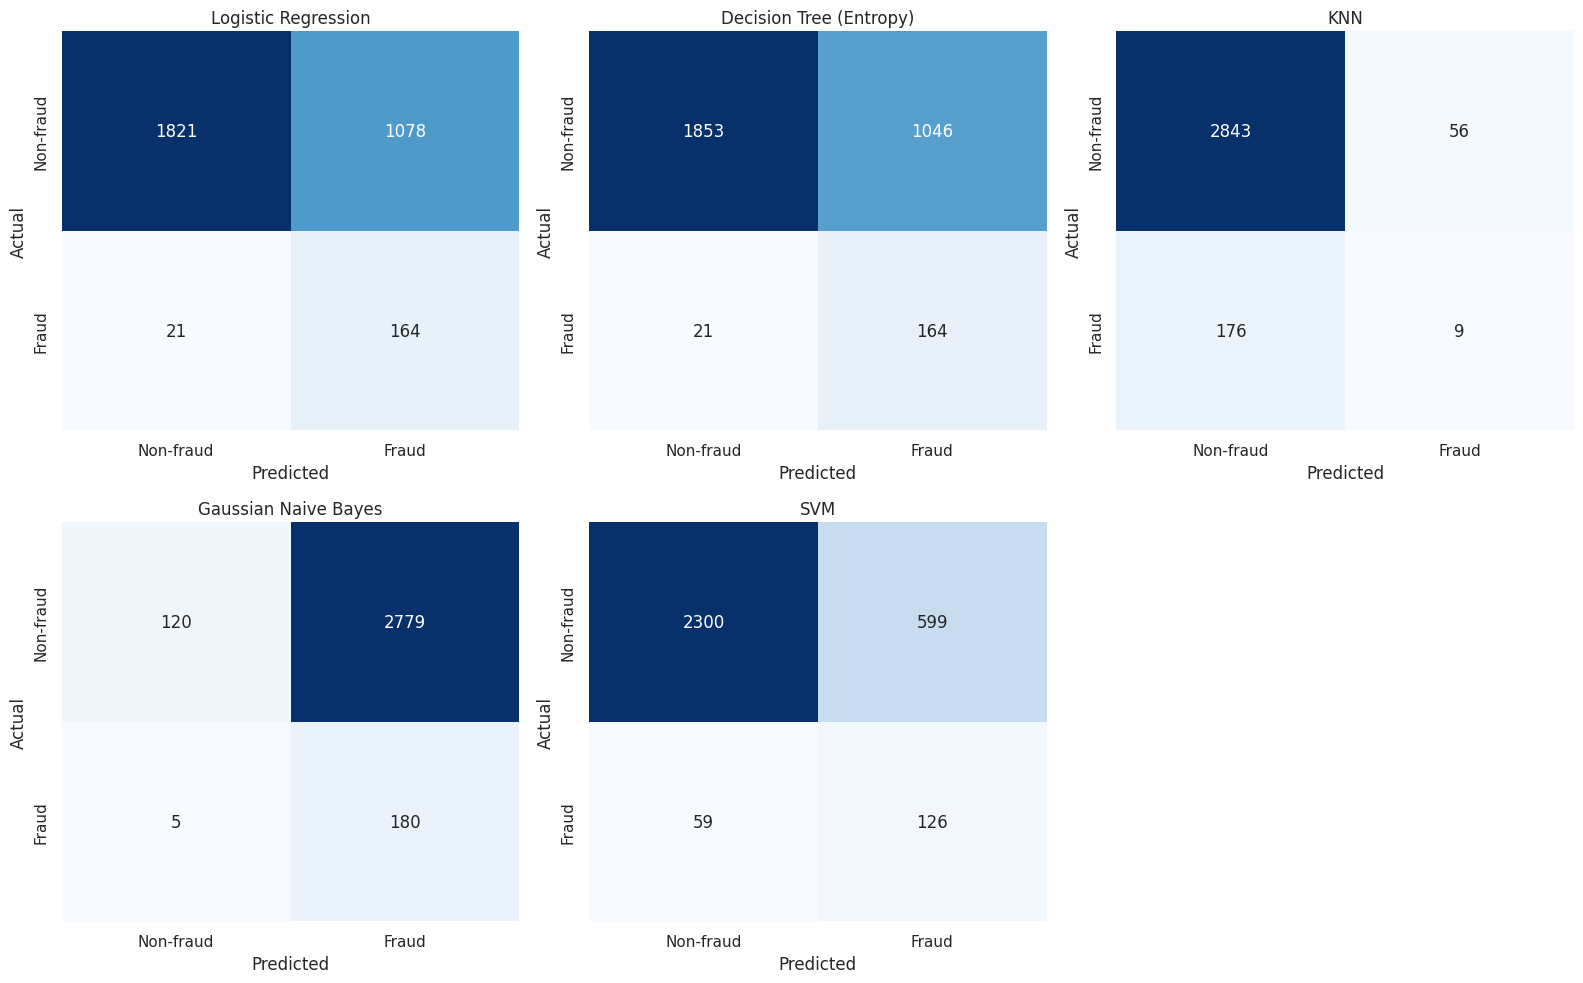

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for position, (model_label, (_, predicted_labels, _)) in enumerate(trained_models.items()):
    matrix = confusion_matrix(y_test, predicted_labels, labels=[0, 1])
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Non-fraud", "Fraud"],
        yticklabels=["Non-fraud", "Fraud"],
        ax=axes[position]
    )
    axes[position].set_title(model_label)
    axes[position].set_xlabel("Predicted")
    axes[position].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

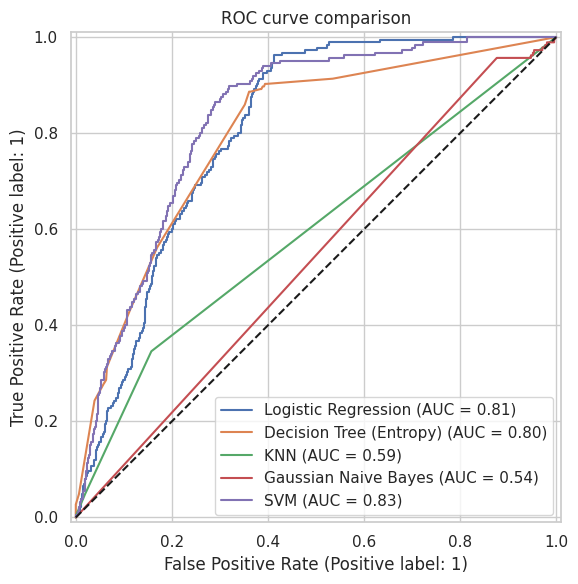

In [28]:
plt.figure(figsize=(8, 6))
for model_label, (_, _, fraud_scores) in trained_models.items():
    RocCurveDisplay.from_predictions(
        y_test, fraud_scores, name=model_label, ax=plt.gca()
    )
plt.plot([0, 1], [0, 1], "k--", label="Random ranking")
plt.title("ROC curve comparison")
plt.tight_layout()
plt.show()

In [29]:
for model_label, (_, predicted_labels, _) in trained_models.items():
    print("\n" + "=" * 65)
    print(model_label)
    print("=" * 65)
    print(classification_report(
        y_test, predicted_labels,
        target_names=["Non-fraud", "Fraud"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

   Non-fraud       0.99      0.63      0.77      2899
       Fraud       0.13      0.89      0.23       185

    accuracy                           0.64      3084
   macro avg       0.56      0.76      0.50      3084
weighted avg       0.94      0.64      0.74      3084


Decision Tree (Entropy)
              precision    recall  f1-score   support

   Non-fraud       0.99      0.64      0.78      2899
       Fraud       0.14      0.89      0.24       185

    accuracy                           0.65      3084
   macro avg       0.56      0.76      0.51      3084
weighted avg       0.94      0.65      0.74      3084


KNN
              precision    recall  f1-score   support

   Non-fraud       0.94      0.98      0.96      2899
       Fraud       0.14      0.05      0.07       185

    accuracy                           0.92      3084
   macro avg       0.54      0.51      0.52      3084
weighted avg       0.89

<a id="part-16"></a>
# <span style="color:#C00000">16. SAVE MODELS AND TEST DATA</span>

Complete pipeline is saved for each classifier, including preprocessing and the fitted estimator because the Streamlit application must apply the same transformations used during training.

The labelled test CSV is retained so that the Streamlit application can calculate evaluation metrics.

In [30]:
model_folder = PROJECT_DIR / "model"
compatibility_model_folder = PROJECT_DIR / "models"
output_folder = PROJECT_DIR / "outputs"
data_folder = PROJECT_DIR / "data"

model_folder.mkdir(exist_ok=True)
compatibility_model_folder.mkdir(exist_ok=True)
output_folder.mkdir(exist_ok=True)

model_file_names = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree (Entropy)": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib"
}

for model_label, (fitted_model, _, _) in trained_models.items():
    joblib.dump(fitted_model, model_folder / model_file_names[model_label])
    # Keep a second copy for compatibility with the companion Streamlit app.
    joblib.dump(fitted_model, compatibility_model_folder / model_file_names[model_label])
    print("Saved:", model_file_names[model_label])

model_results.to_csv(output_folder / "model_comparison.csv", index=False)

test_records = X_test.copy()
test_records[TARGET] = y_test.values
test_records.to_csv(data_folder / "test_data.csv", index=False)

print("\nComparison table saved.")
print("Labelled test data saved.")
print("Model files saved in:", model_folder)
print("Streamlit-compatible copies saved in:", compatibility_model_folder)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib

Comparison table saved.
Labelled test data saved.
Model files saved in: /home/s2025ns04074/workspace/claim_fraud_project/model
Streamlit-compatible copies saved in: /home/s2025ns04074/workspace/claim_fraud_project/models


In [31]:
print("Saved model files:")
for saved_file in sorted(model_folder.glob("*.joblib")):
    print(saved_file.name, "-", f"{saved_file.stat().st_size:,}", "bytes")

print("\nOutput files:")
for saved_file in sorted(output_folder.glob("*")):
    print(saved_file.name)

Saved model files:
decision_tree.joblib - 23,265 bytes
knn.joblib - 14,619,676 bytes
logistic_regression.joblib - 15,111 bytes
naive_bayes.joblib - 18,511 bytes
svm.joblib - 7,325,859 bytes

Output files:
gitkeep
model_comparison.csv
run_metadata.json


### 17.1 Results summary and evidence-based interpretation

Following cell derives the model ranking and observations directly from the metrics calculated in this run. 

In [32]:
# Rank models by F1, then MCC, then ROC-AUC. This gives priority to the positive-class
# precision/recall balance while using two further measures as tie-breakers.
ranked_results = model_results.sort_values(
    by=["F1", "MCC", "AUC"], ascending=False
).reset_index(drop=True)

best_f1 = ranked_results.iloc[0]
best_recall = model_results.loc[model_results["Recall"].idxmax()]
best_precision = model_results.loc[model_results["Precision"].idxmax()]
best_auc = model_results.loc[model_results["AUC"].idxmax()]
best_mcc = model_results.loc[model_results["MCC"].idxmax()]

print("MODEL RANKING (F1, then MCC, then AUC)")
display(ranked_results.style.format({
    "Accuracy":"{:.4f}", "AUC":"{:.4f}", "Precision":"{:.4f}",
    "Recall":"{:.4f}", "F1":"{:.4f}", "MCC":"{:.4f}"
}))
print(f"Highest F1 candidate: {best_f1['Model']} (F1={best_f1['F1']:.4f})")
print(f"Highest recall: {best_recall['Model']} (Recall={best_recall['Recall']:.4f})")
print(f"Highest precision: {best_precision['Model']} (Precision={best_precision['Precision']:.4f})")
print(f"Highest ROC-AUC: {best_auc['Model']} (AUC={best_auc['AUC']:.4f})")
print(f"Highest MCC: {best_mcc['Model']} (MCC={best_mcc['MCC']:.4f})")

# Per-model narrative generated from observed scores.
for _, row in model_results.iterrows():
    print(
        f"{row['Model']}: accuracy {row['Accuracy']:.3f}, "
        f"precision {row['Precision']:.3f}, recall {row['Recall']:.3f}, "
        f"F1 {row['F1']:.3f}, AUC {row['AUC']:.3f}, MCC {row['MCC']:.3f}."
    )

print("\\nInterpretation:")
print(
    f"{best_f1['Model']} is the leading candidate under the stated F1-first "
    f"ranking (F1={best_f1['F1']:.3f}, MCC={best_f1['MCC']:.3f}, "
    f"AUC={best_f1['AUC']:.3f}). This is a comparative result on this "
    "held-out split, not evidence of production suitability."
)
print(
    f"{best_recall['Model']} has the highest fraud recall "
    f"({best_recall['Recall']:.3f}); check its precision and false-positive "
    "count before considering it for an investigation queue."
)
print(
    f"{best_precision['Model']} has the highest fraud precision "
    f"({best_precision['Precision']:.3f}); compare its recall to understand "
    "how many fraud cases it misses."
)

MODEL RANKING (F1, then MCC, then AUC)


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.7866,0.8290,0.1738,0.6811,0.2769,0.2657
1,Decision Tree (Entropy),0.6540,0.7979,0.1355,0.8865,0.2351,0.2557
2,Logistic Regression,0.6436,0.8063,0.1320,0.8865,0.2299,0.2492
3,Gaussian Naive Bayes,0.0973,0.5387,0.0608,0.9730,0.1145,0.0173
4,KNN,0.9248,0.5948,0.1385,0.0486,0.0720,0.0485


Highest F1 candidate: SVM (F1=0.2769)
Highest recall: Gaussian Naive Bayes (Recall=0.9730)
Highest precision: SVM (Precision=0.1738)
Highest ROC-AUC: SVM (AUC=0.8290)
Highest MCC: SVM (MCC=0.2657)
Logistic Regression: accuracy 0.644, precision 0.132, recall 0.886, F1 0.230, AUC 0.806, MCC 0.249.
Decision Tree (Entropy): accuracy 0.654, precision 0.136, recall 0.886, F1 0.235, AUC 0.798, MCC 0.256.
KNN: accuracy 0.925, precision 0.138, recall 0.049, F1 0.072, AUC 0.595, MCC 0.048.
Gaussian Naive Bayes: accuracy 0.097, precision 0.061, recall 0.973, F1 0.115, AUC 0.539, MCC 0.017.
SVM: accuracy 0.787, precision 0.174, recall 0.681, F1 0.277, AUC 0.829, MCC 0.266.
\nInterpretation:
SVM is the leading candidate under the stated F1-first ranking (F1=0.277, MCC=0.266, AUC=0.829). This is a comparative result on this held-out split, not evidence of production suitability.
Gaussian Naive Bayes has the highest fraud recall (0.973); check its precision and false-positive count before considering

### 17.2 Export the experiment results and project summary

 Measured comparison table and a README containing the problem definition, dataset profile, model metrics and results-based observations.

In [33]:
# Save the model comparison results.
output_folder.mkdir(parents=True, exist_ok=True)
data_folder.mkdir(parents=True, exist_ok=True)

model_results.to_csv(
    output_folder / "model_comparison.csv",
    index=False
)

# Rank all five models using the pre-defined selection criteria.
ranked_results = model_results.sort_values(
    by=["F1", "MCC", "AUC"],
    ascending=False
).reset_index(drop=True)

winner = ranked_results.iloc[0]

# Calculate the actual train-test split proportion.
test_size_actual = len(y_test) / (len(y_train) + len(y_test))

# Record the experiment details and evaluation results.
run_details = {
    "project": "Vehicle Insurance Claim Fraud Detection",
    "dataset_source": "Kaggle - Vehicle Claim Fraud Detection",
    "dataset_file": "data/fraud_oracle.csv",
    "dataset_rows": int(claims.shape[0]),
    "dataset_columns_including_target": int(claims.shape[1]),
    "predictor_count": int(X.shape[1]),
    "target": TARGET,
    "target_distribution": {
        str(k): int(v)
        for k, v in y.value_counts().sort_index().items()
    },
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "test_size": round(test_size_actual, 4),
    "random_state": RANDOM_STATE,
    "knn_selected_k": int(
        knn_search.best_params_["classifier__n_neighbors"]
    ),
    "model_selection_rule": "Highest F1, followed by MCC and AUC",
    "models": {
        row["Model"]: {
            metric: round(float(row[metric]), 4)
            for metric in ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
        }
        for _, row in model_results.iterrows()
    },
    "overall_winner": winner["Model"]
}

(output_folder / "run_metadata.json").write_text(
    json.dumps(run_details, indent=4),
    encoding="utf-8"
)

# Build the comparison table in Markdown format.
metric_columns = [
    "Model", "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"
]

metric_table = "| " + " | ".join(metric_columns) + " |\n"
metric_table += "| " + " | ".join(["---"] * len(metric_columns)) + " |\n"

for _, row in model_results[metric_columns].iterrows():
    metric_table += (
        "| " + str(row["Model"]) + " | "
        + " | ".join(f"{row[col]:.4f}" for col in metric_columns[1:])
        + " |\n"
    )

# Generate observations using the measured test results.
majority_accuracy = y_test.value_counts(normalize=True).max()
observations = []

for _, row in model_results.iterrows():

    if row["Accuracy"] <= majority_accuracy + 0.01:
        accuracy_note = (
            "Accuracy is close to the majority-class reference, "
            "so the fraud-class metrics are particularly important."
        )
    else:
        accuracy_note = (
            "Accuracy is above the majority-class reference; "
            "the fraud-class results provide further evidence of performance."
        )

    if row["Precision"] < 0.20 and row["Recall"] >= 0.50:
        fraud_note = (
            "The model identifies a substantial share of actual fraud cases, "
            "but its low precision indicates a high number of false alerts."
        )
    elif row["Precision"] >= 0.20 and row["Recall"] < 0.30:
        fraud_note = (
            "The model has comparatively higher precision, but its low recall "
            "means that many actual fraud cases remain unidentified."
        )
    elif row["Precision"] >= 0.20 and row["Recall"] >= 0.50:
        fraud_note = (
            "The model demonstrates a comparatively balanced precision-recall "
            "profile for identifying fraudulent claims."
        )
    else:
        fraud_note = (
            "The precision-recall results indicate scope for improvement "
            "in identifying fraudulent claims."
        )

    observations.append(
        f"- **{row['Model']}:** {accuracy_note} {fraud_note} "
        f"ROC-AUC = {row['AUC']:.4f}, "
        f"F1 = {row['F1']:.4f}, MCC = {row['MCC']:.4f}."
    )

# Identify the strongest model for each evaluation metric.
best_accuracy = model_results.loc[model_results["Accuracy"].idxmax()]
best_auc = model_results.loc[model_results["AUC"].idxmax()]
best_precision = model_results.loc[model_results["Precision"].idxmax()]
best_recall = model_results.loc[model_results["Recall"].idxmax()]
best_f1 = model_results.loc[model_results["F1"].idxmax()]
best_mcc = model_results.loc[model_results["MCC"].idxmax()]

# Repository link to be updated after the new GitHub repository is created.
github_url = "https://github.com/YOUR_USERNAME/claim-fraud-detection-ml"

# Prepare the final README content.
readme_text = f"""# Vehicle Insurance Claim Fraud Detection

## 1. Problem statement

Vehicle insurance claim fraud is a classification problem in which historical
claim, policy, vehicle and claimant information is used to distinguish between
potentially fraudulent and non-fraudulent claims.

The target variable is `FraudFound_P`:

- `0` – Non-fraudulent claim
- `1` – Fraudulent claim

The objective is to compare five machine learning classifiers and evaluate
their ability to identify potentially fraudulent insurance claims.
Predictions are intended to support further human investigation and do not
establish fraud on their own.

## 2. Dataset description

- **Source:** [Kaggle – Vehicle Claim Fraud Detection](https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection)
- **Dataset file:** `data/fraud_oracle.csv`
- **Total records:** {claims.shape[0]:,}
- **Total columns including target:** {claims.shape[1]}
- **Predictor features used:** {X.shape[1]}
- **Target variable:** `{TARGET}`
- **Non-fraudulent records:** {int((y == 0).sum()):,}
- **Fraudulent records:** {int((y == 1).sum()):,}
- **Training records:** {len(X_train):,}
- **Testing records:** {len(X_test):,}
- **Train-test approach:** Stratified train-test split
- **Random state:** {RANDOM_STATE}

The dataset represents historical vehicle insurance claims.
It is not proprietary data from ICICI Lombard and is not presented
as an Indian insurer dataset.

## 3. GitHub repository

[Project source code and files]({github_url})

## 4. Models used and evaluation metrics

All five classifiers were evaluated using the same training and testing
partitions. The fraud class (`1`) was treated as the positive class when
calculating Precision, Recall, F1 and MCC. AUC represents binary ROC-AUC.

{metric_table}

### Model-wise observations

{chr(10).join(observations)}

### Overall winner for the dataset

**{winner['Model']}**

The model achieved the highest F1-score under the selected ranking criteria,
with an F1-score of {winner['F1']:.4f}, MCC of {winner['MCC']:.4f}
and ROC-AUC of {winner['AUC']:.4f}.

The individual metric leaders were:

- Highest Accuracy: {best_accuracy['Model']} ({best_accuracy['Accuracy']:.4f})
- Highest AUC: {best_auc['Model']} ({best_auc['AUC']:.4f})
- Highest Precision: {best_precision['Model']} ({best_precision['Precision']:.4f})
- Highest Recall: {best_recall['Model']} ({best_recall['Recall']:.4f})
- Highest F1: {best_f1['Model']} ({best_f1['F1']:.4f})
- Highest MCC: {best_mcc['Model']} ({best_mcc['MCC']:.4f})

The overall ranking is based on the current held-out test results.
It does not establish production readiness or guarantee performance
on other datasets.

## 5. Project files

- `notebooks/fraud_detection.ipynb` – Data analysis, preprocessing,
  model development and evaluation.
- `app.py` – Streamlit application for model-based claim assessment.
- `requirements.txt` – Python package dependencies.
- `environment.yml` – Environment specification.
- `data/fraud_oracle.csv` – Original dataset.
- `data/test_data.csv` – Labelled test dataset.
- `model/` – Saved trained model pipelines.
- `models/` – Model copies used by the Streamlit application.
- `outputs/model_comparison.csv` – Model comparison results.
- `outputs/run_metadata.json` – Experiment configuration and results.
"""

(PROJECT_DIR / "README.md").write_text(
    readme_text,
    encoding="utf-8"
)

print("Experiment results exported successfully.")
print("Model comparison:", output_folder / "model_comparison.csv")
print("Run metadata:", output_folder / "run_metadata.json")
print("README:", PROJECT_DIR / "README.md")
print("\nOverall winner:", winner["Model"])
print(
    f"F1 = {winner['F1']:.4f} | "
    f"MCC = {winner['MCC']:.4f} | "
    f"AUC = {winner['AUC']:.4f}"
)

Experiment results exported successfully.
Model comparison: /home/s2025ns04074/workspace/claim_fraud_project/outputs/model_comparison.csv
Run metadata: /home/s2025ns04074/workspace/claim_fraud_project/outputs/run_metadata.json
README: /home/s2025ns04074/workspace/claim_fraud_project/README.md

Overall winner: SVM
F1 = 0.2769 | MCC = 0.2657 | AUC = 0.8290


<a id="part-17"></a>
# <span style="color:#C00000">17. LIMITATIONS AND CONCLUSION</span>

## 17.3 Limitations

- The dataset is historical and may not represent current insurance processes.
- It is a vehicle insurance dataset and does not represent proprietary data from any specific insurer.
- The fraud class is a small proportion of the records; accuracy alone is not sufficient to assess performance.
- False positives can increase investigation workload, while false negatives represent fraud cases not identified by the model.
- The results from one train/test split do not establish generalisation to another insurer, geography or time period.
- Predictions should only support human review and must not be treated as proof of fraud.

## 17.4 Conclusion

The study compares Logistic Regression, Decision Tree, K-Nearest Neighbours, Gaussian Naive Bayes and Support Vector Machine on a common stratified hold-out set. The final candidate is selected using the observed F1-score, with MCC and ROC-AUC as tie-breakers. The selected model requires further validation and threshold assessment before any operational use.

The BITS Virtual Lab screenshot and live deployment link are captured outside this notebook after the application has been deployed and tested.